# Statistical Analysis

## Project Objective

The objective of this statistical analysis is to identify significant patterns, relationships, and business insights from Steam game data using statistical testing techniques.

This analysis evaluates whether factors such as game pricing, discount strategies, and player review behavior influence customer satisfaction and overall game performance on the Steam platform.

---

## Dataset Overview

- **Dataset:** Steam Games Dataset

- **Total Records:** 71,649 Games

- **Total Features:** 21 Columns

### Variables Used for Statistical Analysis

- Original Price
- Discount Percentage
- All Review Percentage
- All Review Count
- Release Year

---

## Statistical Methods Used

The following statistical techniques were applied:

### 1. One-Sample T-Test

Used to determine whether the average Steam game rating differs significantly from a benchmark rating of 70%.

### 2. Independent Two-Sample T-Test

Used to compare average ratings between discounted and non-discounted games.

### 3. One-Way ANOVA

Used to determine whether average ratings differ across different game price categories.

### 4. Pearson Correlation

Used to measure the strength and direction of the relationship between game price and player ratings.

### 5. Linear Regression

Used to evaluate whether game price can predict player ratings.

---

## Significance Level

For all statistical tests, a significance level (**α = 0.05**) was used.

### Decision Rule

- If **P-Value < 0.05** → Reject H₀ (Null Hypothesis)

- If **P-Value ≥ 0.05** → Fail to Reject H₀ (Null Hypothesis)

---

## Expected Business Outcomes

This analysis helps answer important business questions such as:

- Are Steam game ratings generally positive?
- Do discounts influence customer satisfaction?
- Do premium-priced games receive different ratings than low-priced games?
- Is there a meaningful relationship between game price and player ratings?
- Can game pricing be used to predict customer satisfaction?

The findings provide data-driven insights that support pricing strategy, customer experience analysis, game publishing decisions, product positioning, and market intelligence within the gaming industry.

---

01. IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np

from scipy.stats import (
    ttest_1samp,
    ttest_ind,
    f_oneway,
    pearsonr,
    linregress
)

import matplotlib.pyplot as plt

02. LOAD DATA

In [2]:
df = pd.read_csv(
    "../data/processed/game_cleaned.csv"
)

print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

df.head()

Rows : 71649
Columns : 21


,Title,original_price,discounted_price,discount_amount,discount_percentage,release_date,release_year,Link,Game Description,Recent Reviews Summary,...,recent_review_percentage,recent_review_count,all_review_percentage,all_review_count,Developer,Publisher,Supported Languages,Popular Tags,Game Features,Minimum Requirements
0,Baldur's Gate 3,29.99,29.99,0.00,0.0,2023-08-03,2023.0,https://store.steampowered.com/app/1086940/Bal...,"Baldur’s Gate 3 is a story-rich, party-based R...",Overwhelmingly Positive,...,96.0,128900.0,94.0,188617.0,Larian Studios,Larian Studios,"['English', 'French', 'German', 'Spanish - Spa...","['RPG', 'Choices Matter', 'Character Customiza...","['Single-player', 'Online Co-op', 'LAN Co-op',...",Requires a 64-bit processor and operating syst...
1,Counter-Strike: Global Offensive,14.99,14.99,0.00,0.0,2012-08-21,2012.0,https://store.steampowered.com/app/730/Counter...,Counter-Strike: Global Offensive (CS: GO) expa...,Very Positive,...,89.0,75284.0,88.0,7428921.0,"Valve, Hidden Path Entertainment",Valve,"['English', 'Czech', 'Danish', 'Dutch', 'Finni...","['FPS', 'Shooter', 'Multiplayer', 'Competitive...","['Steam Achievements', 'Full controller suppor...",OS: | Windows® 7/Vista/XP | Processor: | Int...
2,Apex Legends™,0.00,0.00,0.00,0.0,2020-11-04,2020.0,https://store.steampowered.com/app/1172470/Ape...,"Apex Legends is the award-winning, free-to-pla...",Mixed,...,65.0,18581.0,80.0,701597.0,Respawn Entertainment,Electronic Arts,"['English', 'French', 'Italian', 'German', 'Sp...","['Free to Play', 'Multiplayer', 'Battle Royale...","['Online PvP', 'Online Co-op', 'Steam Achievem...",Requires a 64-bit processor and operating syst...
3,Forza Horizon 5,34.78,17.39,17.39,50.0,2021-11-08,2021.0,https://store.steampowered.com/app/1551360/For...,Your Ultimate Horizon Adventure awaits! Explor...,Very Positive,...,87.0,4120.0,88.0,123162.0,Playground Games,Xbox Game Studios,"['English', 'French', 'Italian', 'German', 'Sp...","['Racing', 'Open World', 'Driving', 'Multiplay...","['Single-player', 'Online PvP', 'Online Co-op'...",Requires a 64-bit processor and operating syst...
4,Call of Duty®,0.00,0.00,0.00,0.0,2022-10-27,2022.0,https://store.steampowered.com/app/1938090/Cal...,"Welcome to Call of Duty® HQ, the home of Call ...",Mixed,...,49.0,8257.0,57.0,236876.0,"Infinity Ward, Raven Software, Beenox, Treyarc...",Activision,"['English', 'French', 'Italian', 'German', 'Sp...","['FPS', 'Multiplayer', 'Shooter', 'Action', 'S...","['Single-player', 'Online PvP', 'Online Co-op'...",Requires a 64-bit processor and operating syst...


03. DATA PREPARATION

In [3]:
df = df[
    [
        "original_price",
        "discount_percentage",
        "all_review_percentage",
        "all_review_count",
        "release_year"
    ]
].copy()

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 71649 entries, 0 to 71648
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   original_price         71649 non-null  float64
 1   discount_percentage    71649 non-null  float64
 2   all_review_percentage  5371 non-null   float64
 3   all_review_count       5371 non-null   float64
 4   release_year           61344 non-null  float64
dtypes: float64(5)
memory usage: 2.7 MB


In [5]:
df.isnull().sum()

original_price               0
discount_percentage          0
all_review_percentage    66278
all_review_count         66278
release_year             10305
dtype: int64

In [6]:
# Remove rows with missing review data

stats_df = df.dropna(
    subset=[
        "all_review_percentage",
        "all_review_count"
    ]
).copy()

print("Records Used For Statistical Analysis:")
print(stats_df.shape[0])

Records Used For Statistical Analysis:
5371


In [7]:
stats_df.isnull().sum()

original_price            0
discount_percentage       0
all_review_percentage     0
all_review_count          0
release_year             27
dtype: int64

In [8]:
stats_df.describe()

,original_price,discount_percentage,all_review_percentage,all_review_count,release_year
count,5371.000000,5371.000000,5371.000000,5.371000e+03,5344.000000
mean,10.542054,3.138298,84.951592,1.523301e+04,2018.904004
std,11.322809,13.671383,11.466325,1.209088e+05,3.748498
min,0.000000,0.000000,12.000000,1.100000e+01,2002.000000
25%,2.990000,0.000000,80.000000,8.810000e+02,2017.000000
50%,8.490000,0.000000,88.000000,2.492000e+03,2020.000000
75%,12.990000,0.000000,93.000000,7.568000e+03,2022.000000
max,145.140000,99.000000,100.000000,7.428921e+06,2023.000000


# Data Preparation Conclusion

## Summary

- Selected **5 key variables** for statistical analysis:
  - Original Price
  - Discount Percentage
  - Review Percentage
  - Review Count
  - Release Year

- Removed records with missing review information.

- Final dataset contains **5,371 Steam games** with valid review data.

## Key Observations

- Average game price: **$10.54**
- Average review rating: **84.95%**
- Average review count: **15,233**
- Average release year: **2019**
- Most games receive positive player ratings.

## Statistical Readiness

The dataset has been cleaned, validated, and prepared for hypothesis testing. All subsequent statistical analyses will be performed using the final dataset of **5,371 reviewed Steam games**.

## Statistical Analysis Using Hypothesis Testing

## 1. One-Sample T-Test

**Business Question:** Is the average Steam game rating significantly different from 70%?

**Why use it?**

- Compare dataset mean rating against a benchmark (70%).

**Variables Used**

- `all_review_percentage`

In [9]:
from scipy.stats import ttest_1samp

benchmark_rating = 70

t_stat, p_value = ttest_1samp(
    stats_df["all_review_percentage"],
    popmean=benchmark_rating
)

print(
    "Average Rating:",
    round(stats_df["all_review_percentage"].mean(), 2)
)

print(
    "T-Statistic:",
    round(t_stat, 2)
)

print(
    "P-Value:",
    p_value
)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Average Rating: 84.95
T-Statistic: 95.56
P-Value: 0.0
Reject H0


## ONE-SAMPLE T-TEST Conclusion

### Business Question

Is the average Steam game rating significantly different from 70%?

### Variable Used

- all_review_percentage

### Hypotheses

**H₀ (Null Hypothesis):**

The average Steam game rating is equal to 70%.

**H₁ (Alternative Hypothesis):**

The average Steam game rating is significantly different from 70%.

### Results

- Average Rating: **84.95%**
- T-Statistic: **95.56**
- P-Value: **< 0.0001**

### Statistical Interpretation

Since the p-value is less than 0.05, the null hypothesis (H₀) is rejected. There is sufficient statistical evidence to conclude that the average Steam game rating differs significantly from the benchmark rating of 70%.

### Business Conclusion

The average Steam game rating of **84.95%** is significantly higher than the benchmark rating of **70%**, indicating strong overall player satisfaction.

### Key Insight

Most Steam games receive favorable ratings, suggesting that the platform hosts a generally well-received game catalog.

### Business Impact

This analysis helps assess overall platform quality and provides evidence that Steam maintains a strong user satisfaction level.

## 2. Independent T-Test

**Business Question:** Do discounted games have different ratings than non-discounted games?

**Why use it?**

- Compare means of two independent groups.

**Variables Used**

- `discount_percentage`
- `all_review_percentage`

In [10]:
from scipy.stats import ttest_ind

discounted_games = stats_df[
    stats_df["discount_percentage"] > 0
]["all_review_percentage"]

non_discounted_games = stats_df[
    stats_df["discount_percentage"] == 0
]["all_review_percentage"]

t_stat, p_value = ttest_ind(
    discounted_games,
    non_discounted_games,
    equal_var=False
)

print(
    "Discounted Games Average Rating:",
    round(discounted_games.mean(), 2)
)

print(
    "Non-Discounted Games Average Rating:",
    round(non_discounted_games.mean(), 2)
)

print(
    "T-Statistic:",
    round(t_stat, 2)
)

print(
    "P-Value:",
    p_value
)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Discounted Games Average Rating: 83.89
Non-Discounted Games Average Rating: 85.02
T-Statistic: -1.75
P-Value: 0.08169773741112177
Fail to Reject H0


## INDEPENDENT T-TEST Conclusion

### Business Question

Do discounted Steam games receive significantly different ratings compared to non-discounted games?

### Variable Used

- discount_percentage
- all_review_percentage

### Hypotheses

**H₀ (Null Hypothesis):**

There is no significant difference between the average ratings of discounted and non-discounted Steam games.

**H₁ (Alternative Hypothesis):**

There is a significant difference between the average ratings of discounted and non-discounted Steam games.

### Results

- Discounted Games Average Rating: **83.89%**
- Non-Discounted Games Average Rating: **85.02%**
- T-Statistic: **-1.75**
- P-Value: **0.0817**

### Statistical Interpretation

Since the p-value is greater than 0.05, the null hypothesis (H₀) cannot be rejected. There is insufficient statistical evidence to conclude that discounted and non-discounted Steam games have significantly different average ratings.

### Business Conclusion

Although non-discounted games have a slightly higher average rating (**85.02%**) than discounted games (**83.89%**), the difference is not statistically significant.

### Key Insight

Offering discounts does not appear to have a meaningful impact on player ratings. Game quality and player satisfaction are likely influenced by factors other than pricing promotions.

### Business Impact

This finding suggests that discount strategies can be used to increase sales and visibility without significantly affecting player review ratings. Developers and publishers can focus on product quality while using discounts as a marketing tool.

## 3. One-Way ANOVA

**Business Question:** Do game ratings differ across price categories?

**Why use it?**

- Compare means across more than two groups.

**Groups**

- Cheap (< $10)
- Medium ($10–$30)
- Premium (> $30)

**Variables Used**

- `original_price`
- `all_review_percentage`

In [11]:
from scipy.stats import f_oneway

cheap = stats_df[
    stats_df["original_price"] < 10
]["all_review_percentage"]

medium = stats_df[
    (stats_df["original_price"] >= 10) &
    (stats_df["original_price"] <= 30)
]["all_review_percentage"]

premium = stats_df[
    stats_df["original_price"] > 30
]["all_review_percentage"]

print("Cheap Games:", len(cheap))
print("Medium Games:", len(medium))
print("Premium Games:", len(premium))

f_stat, p_value = f_oneway(
    cheap,
    medium,
    premium
)

print(
    "\nCheap Games Average Rating:",
    round(cheap.mean(), 2)
)

print(
    "Medium Games Average Rating:",
    round(medium.mean(), 2)
)

print(
    "Premium Games Average Rating:",
    round(premium.mean(), 2)
)

print(
    "F-Statistic:",
    round(f_stat, 2)
)

print(
    "P-Value:",
    p_value
)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Cheap Games: 3050
Medium Games: 2070
Premium Games: 251

Cheap Games Average Rating: 85.76
Medium Games Average Rating: 84.59
Premium Games Average Rating: 78.05
F-Statistic: 55.19
P-Value: 1.8749083426200997e-24
Reject H0


## ONE-WAY ANOVA Conclusion

### Business Question

Do game ratings differ across price categories?

### Variable Used

- original_price
- all_review_percentage

### Groups

- Cheap Games (< $10)
- Medium Games ($10 – $30)
- Premium Games (> $30)

### Hypotheses

**H₀ (Null Hypothesis):**

The average game rating is the same across all price categories.

**H₁ (Alternative Hypothesis):**

At least one price category has a significantly different average rating.

### Results

#### Group Sizes

- Cheap Games: **3,050**
- Medium Games: **2,070**
- Premium Games: **251**

#### Average Ratings

- Cheap Games Average Rating: **85.76%**
- Medium Games Average Rating: **84.59%**
- Premium Games Average Rating: **78.05%**

#### Test Statistics

- F-Statistic: **55.19**
- P-Value: **< 0.0001**

### Statistical Interpretation

Since the p-value is less than 0.05, the null hypothesis (H₀) is rejected. There is sufficient statistical evidence to conclude that average game ratings differ significantly across price categories.

### Business Conclusion

Game ratings vary significantly based on price category. Cheap and medium-priced games receive higher average ratings than premium-priced games, with premium games showing the lowest average rating (**78.05%**).

### Key Insight

Lower-priced games tend to achieve stronger player satisfaction scores, while premium-priced games face higher player expectations and receive comparatively lower ratings.

### Business Impact

This finding suggests that pricing strategy may influence customer perception and satisfaction. Developers launching premium-priced games should focus heavily on delivering exceptional value and quality to meet player expectations and maintain strong review ratings.

## 4. Pearson Correlation

**Business Question:** Is there a linear relationship between price and rating?

**Why use it?**

- Measures the strength and direction of a linear relationship between two continuous variables.

**Variables Used**

- `original_price`
- `all_review_percentage`

In [12]:
from scipy.stats import pearsonr

correlation, p_value = pearsonr(
    stats_df["original_price"],
    stats_df["all_review_percentage"]
)

print("Correlation Coefficient:", round(correlation, 4))
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Correlation Coefficient: -0.1203
P-Value: 9.072873809358359e-19
Reject H0


## PEARSON CORRELATION Conclusion

### Business Question

Is there a linear relationship between game price and player ratings?

### Variable Used

- `original_price`
- `all_review_percentage`

### Hypotheses

**H₀ (Null Hypothesis):**

There is no linear relationship between game price and player ratings.

**H₁ (Alternative Hypothesis):**

There is a significant linear relationship between game price and player ratings.

### Results

- Correlation Coefficient (r): **-0.1203**
- P-Value: **9.07 × 10⁻¹⁹**
- Decision: **Reject H₀**

### Statistical Interpretation

Since the p-value is less than 0.05, the null hypothesis (H₀) is rejected. There is sufficient statistical evidence to conclude that a statistically significant relationship exists between game price and player ratings.

The correlation coefficient of **-0.1203** indicates a **very weak negative relationship** between price and rating.

### Business Conclusion

Higher-priced games tend to receive slightly lower ratings on average, but the relationship is very weak. Game price alone is not a strong predictor of player satisfaction.

### Key Insight

Players do not necessarily rate expensive games more favorably. Affordable games can achieve ratings comparable to or even better than premium-priced titles.

### Business Impact

Game developers and publishers should focus on delivering quality gameplay and user experience rather than relying solely on premium pricing. Pricing strategy has limited influence on review performance compared to overall game quality.

## 5. Chi-Square Test of Independence

**Business Question:** Is rating category associated with discount category?

**Why use it?**

- Tests whether two categorical variables are statistically associated.

**Variables Used**

- `rating_group`
- `discount_group`

In [13]:
from scipy.stats import chi2_contingency
import pandas as pd

# Create Rating Categories
stats_df["rating_group"] = pd.cut(
    stats_df["all_review_percentage"],
    bins=[0, 80, 90, 100],
    labels=["Low", "Medium", "High"]
)

# Create Discount Categories
stats_df["discount_group"] = pd.cut(
    stats_df["discount_percentage"],
    bins=[-1, 0, 50, 100],
    labels=["No Discount", "Moderate Discount", "Heavy Discount"]
)

# Distribution of Categories
print("Rating Group Distribution")
print(stats_df["rating_group"].value_counts())

print("\nDiscount Group Distribution")
print(stats_df["discount_group"].value_counts())

# Contingency Table
contingency_table = pd.crosstab(
    stats_df["rating_group"],
    stats_df["discount_group"]
)

print("\nContingency Table")
print(contingency_table)

# Chi-Square Test
chi2_stat, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("\nChi-Square Statistic:", round(chi2_stat, 2))
print("Degrees of Freedom:", dof)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Rating Group Distribution
rating_group
High      2099
Medium    1813
Low       1459
Name: count, dtype: int64

Discount Group Distribution
discount_group
No Discount          5044
Heavy Discount        183
Moderate Discount     144
Name: count, dtype: int64

Contingency Table
discount_group  No Discount  Moderate Discount  Heavy Discount
rating_group                                                  
Low                    1351                 45              63
Medium                 1700                 48              65
High                   1993                 51              55

Chi-Square Statistic: 9.44
Degrees of Freedom: 4
P-Value: 0.05107820098404157
Fail to Reject H0


## CHI-SQUARE TEST OF INDEPENDENCE Conclusion

### Business Question

Is rating category associated with discount category?

### Variables Used

- rating_group
- discount_group

### Hypotheses

**H₀ (Null Hypothesis):**

There is no association between rating category and discount category.

**H₁ (Alternative Hypothesis):**

There is a significant association between rating category and discount category.

### Results

#### Rating Group Distribution

- High Rated Games: **2,099**
- Medium Rated Games: **1,813**
- Low Rated Games: **1,459**

#### Discount Group Distribution

- No Discount: **5,044**
- Moderate Discount: **144**
- Heavy Discount: **183**

#### Test Statistics

- Chi-Square Statistic: **9.44**
- Degrees of Freedom: **4**
- P-Value: **0.0511**

### Statistical Interpretation

Since the p-value (**0.0511**) is slightly greater than the significance level of **0.05**, we fail to reject the null hypothesis (H₀).

There is insufficient statistical evidence to conclude that rating category and discount category are associated.

### Business Conclusion

Game ratings appear to be largely independent of discount levels. Highly rated, medium-rated, and low-rated games are distributed similarly across discount categories.

### Key Insight

Discounting does not appear to significantly influence a game's rating category. Players may evaluate games primarily based on gameplay quality rather than discounts.

### Business Impact

Steam publishers should not rely solely on discount strategies to improve perceived game quality. While discounts may help increase sales volume, maintaining strong game quality remains the primary driver of positive player ratings.

# 06. Linear Regression

## Business Question

Does game price significantly influence game ratings?

## Why Use It?

- Predicts the effect of one variable on another.
- Measures how much ratings change as price changes.
- Helps quantify the relationship identified in correlation analysis.

## Variables Used

- `original_price` (Independent Variable X)
- `all_review_percentage` (Dependent Variable Y)

## Hypotheses

**H₀ (Null Hypothesis):**

Game price has no significant effect on game ratings.

**H₁ (Alternative Hypothesis):**

Game price has a significant effect on game ratings.

In [14]:
from scipy.stats import linregress

result = linregress(
    stats_df["original_price"],
    stats_df["all_review_percentage"]
)

print("Slope:", round(result.slope, 4))
print("Intercept:", round(result.intercept, 4))

print("Correlation:", round(result.rvalue, 4))

print("R-Squared:", round(result.rvalue**2, 4))

print("P-Value:", result.pvalue)

if result.pvalue < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Slope: -0.1218
Intercept: 86.2358
Correlation: -0.1203
R-Squared: 0.0145
P-Value: 9.072873809359114e-19
Reject H0


## LINEAR REGRESSION Conclusion

### Business Question

Does game price significantly influence game ratings?

### Variables Used

- original_price (Independent Variable X)
- all_review_percentage (Dependent Variable Y)

### Hypotheses

**H₀ (Null Hypothesis):**

Game price has no significant effect on game ratings.

**H₁ (Alternative Hypothesis):**

Game price has a significant effect on game ratings.

### Results

- Slope: **-0.1218**
- Intercept: **86.2358**
- Correlation (r): **-0.1203**
- R-Squared (R²): **0.0145**
- P-Value: **< 0.0001**

### Statistical Interpretation

Since the p-value is less than 0.05, the null hypothesis (H₀) is rejected.

There is sufficient statistical evidence to conclude that game price has a statistically significant effect on game ratings.

However, the correlation coefficient (**-0.1203**) indicates a very weak negative relationship between price and ratings.

The R-Squared value (**0.0145**) shows that game price explains only **1.45%** of the variation in game ratings.

### Business Conclusion

Higher-priced games tend to receive slightly lower ratings on average, but the effect is very small. Game price alone is not a strong predictor of player satisfaction.

### Key Insight

Factors other than price—such as gameplay quality, user experience, developer reputation, and content value—play a much larger role in determining game ratings.

### Business Impact

Pricing decisions should not be used as the primary strategy for improving player ratings. Steam publishers should focus on game quality and player experience, as price explains only a small portion of rating performance.

# Statistical Analysis Visualizations

## 1. Ratings by Price Category (Supports ANOVA)

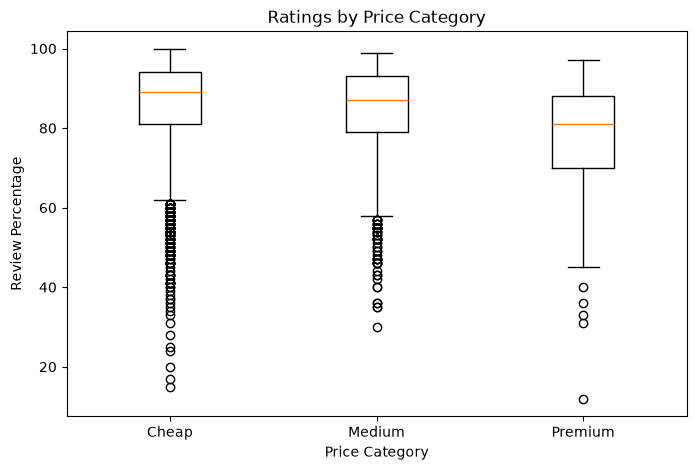

In [15]:
import matplotlib.pyplot as plt

cheap = stats_df[
    stats_df["original_price"] < 10
]["all_review_percentage"]

medium = stats_df[
    (stats_df["original_price"] >= 10) &
    (stats_df["original_price"] <= 30)
]["all_review_percentage"]

premium = stats_df[
    stats_df["original_price"] > 30
]["all_review_percentage"]

plt.figure(figsize=(8,5))

plt.boxplot(
    [cheap, medium, premium],
    tick_labels=["Cheap", "Medium", "Premium"]
)

plt.title("Ratings by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Review Percentage")

plt.show()

### Visualization Insights

- Cheap games show the highest median rating (~89%), followed by medium-priced games (~87%).
- Premium games have a lower median rating (~81%) compared to cheaper categories.
- Rating variability is similar across all price categories.
- All three groups contain some low-rated outlier games.
- Higher-priced games do not necessarily receive better player ratings.

### Business Insight

The visualization suggests that lower-priced games generally achieve stronger player satisfaction than premium-priced games. This supports the ANOVA result that game ratings differ significantly across price categories.

# 2. Price vs Rating Scatter Plot (Supports Pearson Correlation & Linear Regression)

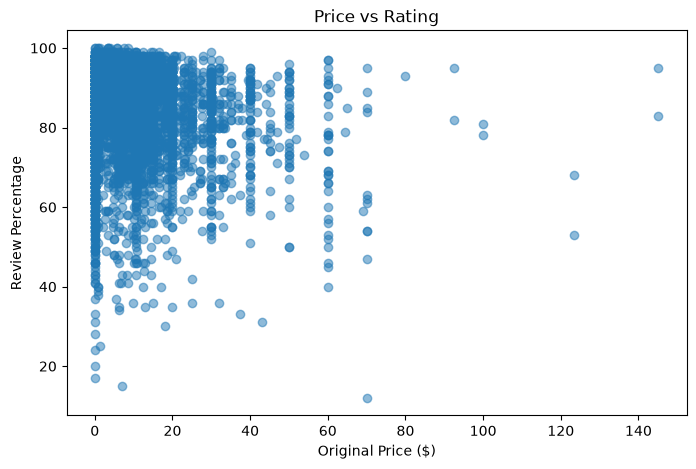

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(
    stats_df["original_price"],
    stats_df["all_review_percentage"],
    alpha=0.5
)

plt.title("Price vs Rating")
plt.xlabel("Original Price ($)")
plt.ylabel("Review Percentage")

plt.show()

## Visualization Insight – Price vs Rating Scatter Plot

### Key Observations

- Most Steam games are priced below **$20**, creating a dense cluster on the left side of the chart.
- Review ratings are generally high across all price ranges, with many games receiving ratings above **80%**.
- Higher-priced games do not consistently achieve higher ratings than lower-priced games.
- Several low-priced games receive extremely high ratings, indicating strong player satisfaction despite lower prices.
- A few premium-priced games show moderate or low ratings, suggesting that higher prices do not guarantee better user reviews.

### Statistical Insight

- The scatter plot shows a **weak negative relationship** between price and rating.
- This supports the Pearson Correlation result (**r = -0.1203**) and Linear Regression analysis.
- The relationship is statistically significant but practically very weak.

### Business Conclusion

Game quality and player satisfaction appear to be influenced more by gameplay experience and value delivered rather than price alone. Lower-priced games can achieve ratings comparable to or better than premium-priced titles.

### Business Impact

Steam publishers should focus on product quality, gameplay, and player experience rather than relying solely on premium pricing strategies to drive positive reviews.

# 3. Discount Category vs Rating Category (Supports Chi-Square Test)

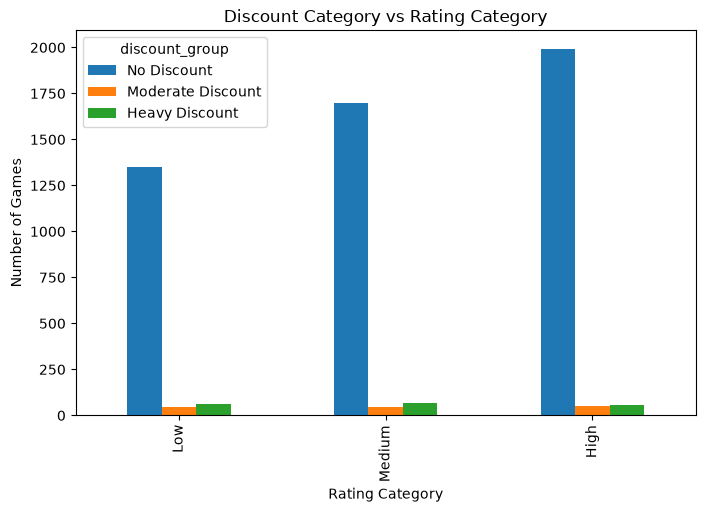

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

analysis_df = stats_df.copy()

analysis_df["rating_group"] = pd.cut(
    analysis_df["all_review_percentage"],
    bins=[0, 80, 90, 100],
    labels=["Low", "Medium", "High"]
)

analysis_df["discount_group"] = pd.cut(
    analysis_df["discount_percentage"],
    bins=[-1, 0, 50, 100],
    labels=[
        "No Discount",
        "Moderate Discount",
        "Heavy Discount"
    ]
)

contingency_table = pd.crosstab(
    analysis_df["rating_group"],
    analysis_df["discount_group"]
)

contingency_table.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Discount Category vs Rating Category")
plt.xlabel("Rating Category")
plt.ylabel("Number of Games")

plt.show()

## Visualization Insight – Discount Category vs Rating Category

### Key Observations

- Most Steam games in all rating categories have **no discount**.
- High-rated games represent the largest group across the dataset.
- Moderate and heavy discounts are relatively uncommon compared to non-discounted games.
- The distribution of discount levels appears similar across Low, Medium, and High rating categories.
- No rating category is overwhelmingly associated with a specific discount category.

### Statistical Insight

- The Chi-Square Test produced a **p-value of 0.0511**, which is slightly greater than the significance level of 0.05.
- Therefore, the null hypothesis was not rejected.
- There is insufficient statistical evidence to conclude that rating category and discount category are associated.

### Business Conclusion

Game ratings do not appear to be strongly influenced by discount levels. Highly rated and lower-rated games can be found across all discount categories.

### Business Impact

Publishers should not rely solely on discount strategies to improve game ratings. Factors such as gameplay quality, content, updates, and user experience are likely more important drivers of player satisfaction.

# Statistical Analysis Summary

| Statistical Test | Result |
|------------------|----------|
| One-Sample T-Test | Average Steam game rating (84.95%) is significantly higher than the benchmark rating of 70% |
| Independent T-Test | No statistically significant difference was found between the ratings of discounted and non-discounted games |
| One-Way ANOVA | Game ratings differ significantly across Cheap, Medium, and Premium price categories |
| Pearson Correlation | Weak negative relationship exists between game price and player ratings (r = -0.1203) |
| Chi-Square Test | No statistically significant association was found between discount categories and rating categories |
| Linear Regression | Game price has a statistically significant but very weak negative effect on ratings (R² = 0.0145) |

---

# Final Statistical Analysis Summary

## Project Objective

The objective of this statistical analysis was to evaluate the relationships between game ratings, pricing, and discount strategies within the Steam Games dataset using statistical hypothesis testing and predictive modeling techniques.

---

## Key Findings

### 1. One-Sample T-Test

The average Steam game rating (**84.95%**) was significantly higher than the benchmark rating of **70%**, indicating that Steam games generally receive positive feedback from players.

### 2. Independent T-Test

No statistically significant difference was found between the ratings of discounted and non-discounted games. Both groups achieved similar average ratings, suggesting that discounts do not substantially affect player satisfaction.

### 3. One-Way ANOVA

Game ratings differed significantly across price categories. Cheap and medium-priced games achieved higher average ratings than premium-priced games, indicating that pricing segments exhibit different player satisfaction patterns.

### 4. Pearson Correlation

A statistically significant but weak negative relationship (**r = -0.1203**) was observed between game price and ratings. Higher-priced games tend to receive slightly lower ratings on average, although the effect is very small.

### 5. Chi-Square Test of Independence

No statistically significant association was found between discount categories and rating categories (**p = 0.0511**). Rating distributions remain largely similar regardless of discount level.

### 6. Linear Regression

Game price was a statistically significant predictor of ratings; however, the model explained only **1.45%** of the variation in ratings (**R² = 0.0145**). This indicates that price alone has very limited predictive power.

---

## Overall Business Insights

- Steam games generally receive strong player ratings, with an average rating of nearly **85%**.
- Ratings are significantly higher than the industry benchmark of **70%**.
- Discounted games and non-discounted games receive similar ratings.
- Ratings vary across price categories, with premium-priced games receiving comparatively lower ratings.
- Higher prices are associated with slightly lower ratings, but the relationship is weak.
- Discount strategies do not appear to significantly influence rating outcomes.
- Game price explains only a small fraction of player satisfaction.
- Other factors beyond pricing are likely responsible for most variations in ratings.

---

## Business Recommendations

1. Focus on improving gameplay quality, user experience, and content value rather than relying heavily on pricing strategies.

2. Use discounts primarily as a sales and acquisition tool rather than expecting them to improve player ratings.

3. Monitor player reviews continuously to identify satisfaction drivers and areas for improvement.

4. Investigate additional factors such as genre, developer reputation, game features, community engagement, and update frequency to better understand rating performance.

5. Build future predictive models using a broader set of variables to improve explanatory power and business decision-making.

---

## Final Conclusion

The statistical analysis reveals that Steam maintains a highly rated gaming ecosystem, with average player ratings significantly exceeding the 70% benchmark. While game ratings vary across price categories, both correlation and regression analyses demonstrate that price has only a weak influence on player satisfaction and explains very little of the variation in ratings.

Furthermore, discounting does not significantly impact rating outcomes, and rating categories are largely independent of discount levels. Overall, the findings suggest that player satisfaction on Steam is driven far more by game quality, content, and user experience than by pricing or discount strategies alone.

The results highlight that delivering engaging gameplay experiences and maintaining strong player value remain the most important factors for achieving positive ratings and long-term success on the Steam platform.